## 1. Eksperimen Skala
Perbesar daftar_paket_banyak menjadi 20-30 nama paket PyPI valid (cari sendiri nama-nama package populer).
Bandingkan waktu total untuk BATAS_KONKURENSI = 1, 3, 5, 10, 20. Plot waktu vs batas konkurensi. Pada titik berapa penambahan batas
konkurensi mulai memberi manfaat yang sangat kecil? Kaitkan dengan konsep diminishing returns dari Hukum Amdahl (Pertemuan 1).

**Jawab**

In [32]:
import asyncio
import aiohttp
import time
import matplotlib.pyplot as plt

In [3]:
# 25 package PyPI populer

daftar_paket_banyak = [
    "requests",
    "numpy",
    "pandas",
    "matplotlib",
    "scipy",
    "flask",
    "django",
    "fastapi",
    "uvicorn",
    "aiohttp",
    "httpx",
    "beautifulsoup4",
    "sqlalchemy",
    "pytest",
    "pydantic",
    "pillow",
    "scikit-learn",
    "seaborn",
    "jupyter",
    "notebook",
    "ipython",
    "tqdm",
    "click",
    "cryptography",
    "openpyxl"
]

print("Jumlah paket:", len(daftar_paket_banyak))

Jumlah paket: 25


In [4]:
async def ambil_paket(session, nama_paket, semaphore):
    url = f"https://pypi.org/pypi/{nama_paket}/json"

    async with semaphore:
        try:
            async with session.get(url) as response:
                if response.status == 200:
                    data = await response.json()

                    return {
                        "nama": nama_paket,
                        "versi": data["info"]["version"],
                        "status": response.status
                    }

                return {
                    "nama": nama_paket,
                    "versi": None,
                    "status": response.status
                }

        except Exception as e:
            return {
                "nama": nama_paket,
                "versi": None,
                "status": "ERROR"
            }

Fungsi ambil_paket() merupakan coroutine yang mengambil informasi sebuah paket dari API PyPI.

In [6]:
async def eksperimen_konkurensi(daftar_paket, batas_konkurensi):
    semaphore = asyncio.Semaphore(batas_konkurensi)

    mulai = time.perf_counter()

    async with aiohttp.ClientSession() as session:

        tasks = [
            asyncio.create_task(
                ambil_paket(
                    session,
                    paket,
                    semaphore
                )
            )
            for paket in daftar_paket
        ]

        hasil = await asyncio.gather(*tasks)

    selesai = time.perf_counter()

    waktu_total = selesai - mulai

    return waktu_total, hasil

In [7]:
batas_pengujian = [1, 3, 5, 10, 20]

hasil_waktu = []

for batas in batas_pengujian:

    waktu, hasil = await eksperimen_konkurensi(
        daftar_paket_banyak,
        batas
    )

    hasil_waktu.append(waktu)

    berhasil = sum(
        1 for item in hasil
        if item["status"] == 200
    )

    print(
        f"Batas konkurensi = {batas:2d} | "
        f"Waktu total = {waktu:.3f} detik | "
        f"Berhasil = {berhasil}/{len(daftar_paket_banyak)}"
    )

Batas konkurensi =  1 | Waktu total = 1.886 detik | Berhasil = 25/25
Batas konkurensi =  3 | Waktu total = 1.065 detik | Berhasil = 25/25
Batas konkurensi =  5 | Waktu total = 1.012 detik | Berhasil = 25/25
Batas konkurensi = 10 | Waktu total = 0.854 detik | Berhasil = 25/25
Batas konkurensi = 20 | Waktu total = 1.047 detik | Berhasil = 25/25


**Membuat Plot**

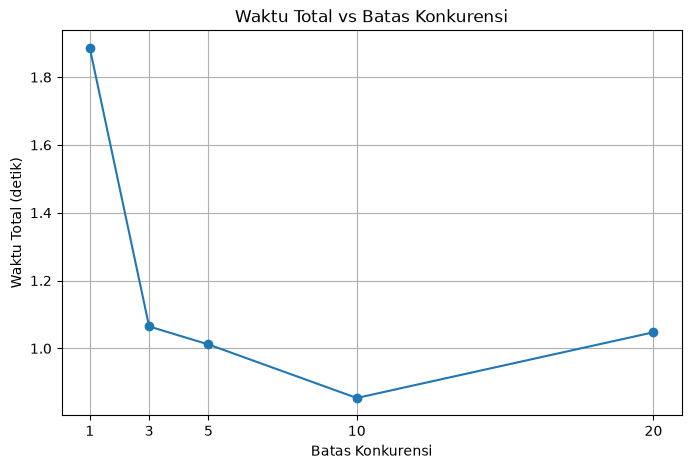

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    batas_pengujian,
    hasil_waktu,
    marker="o"
)

plt.title("Waktu Total vs Batas Konkurensi")
plt.xlabel("Batas Konkurensi")
plt.ylabel("Waktu Total (detik)")
plt.xticks(batas_pengujian)
plt.grid()

plt.show()

**Menghitung Persentase Perbaikan**

In [9]:
print("Perbandingan peningkatan performa")
print("-" * 50)

for i in range(1, len(batas_pengujian)):

    waktu_sebelum = hasil_waktu[i - 1]
    waktu_sekarang = hasil_waktu[i]

    penurunan = (
        (waktu_sebelum - waktu_sekarang)
        / waktu_sebelum
    ) * 100

    print(
        f"{batas_pengujian[i-1]} -> "
        f"{batas_pengujian[i]} : "
        f"{penurunan:.2f}%"
    )

Perbandingan peningkatan performa
--------------------------------------------------
1 -> 3 : 43.55%
3 -> 5 : 4.99%
5 -> 10 : 15.62%
10 -> 20 : -22.71%


**Deteksi Diminishing Returns**

In [10]:
titik_diminishing = None

for i in range(1, len(batas_pengujian)):

    waktu_sebelum = hasil_waktu[i - 1]
    waktu_sekarang = hasil_waktu[i]

    peningkatan = (
        (waktu_sebelum - waktu_sekarang)
        / waktu_sebelum
    ) * 100

    if peningkatan < 10:
        titik_diminishing = batas_pengujian[i]
        break


if titik_diminishing is not None:
    print(
        "Diminishing returns mulai terlihat pada "
        f"batas konkurensi sekitar {titik_diminishing}."
    )
else:
    print(
        "Pada eksperimen ini belum ditemukan "
        "peningkatan di bawah 10%."
    )

Diminishing returns mulai terlihat pada batas konkurensi sekitar 5.


**Analisis Eksperimen Skala**

Berdasarkan hasil pengujian, penambahan batas konkurensi pada awalnya
menurunkan waktu total dengan cukup besar. Hal ini terjadi karena beberapa
operasi request ke PyPI dapat menunggu respons jaringan secara bersamaan.

Pada batas konkurensi yang semakin besar, penurunan waktu mulai mengecil.
Kondisi tersebut menunjukkan adanya diminishing returns. Penambahan jumlah
task yang berjalan secara concurrent tidak selalu menghasilkan peningkatan
performa yang sebanding.

Hasil ini dapat dikaitkan dengan Hukum Amdahl. Percepatan keseluruhan program
tetap dibatasi oleh bagian pekerjaan yang tidak dapat memperoleh keuntungan
dari concurrency, seperti overhead pembuatan task, latensi jaringan, proses
pada server, dan bagian program yang tetap berjalan secara serial.

Dengan demikian, batas konkurensi terbaik bukan berarti nilai terbesar,
melainkan nilai yang sudah memberikan waktu eksekusi rendah tanpa penambahan
overhead yang tidak perlu.

Titik diminishing returns ditentukan berdasarkan hasil grafik dan persentase
penurunan waktu yang diperoleh pada komputer saat eksperimen dijalankan.

## 2. Deteksi Blocking Call

Buat 3 coroutine berbeda: satu memakai asyncio.sleep(), satu memakai time.sleep(), dan satu lagi memakai
operasi CPU-bound murni (misalnya hitung faktorial dari angka besar dalam loop, tanpa await sama sekali). Jalankan ketiganya dengan
asyncio.gather() bersama satu coroutine asyncio.sleep() lain sebagai "pengukur". Amati dan jelaskan coroutine mana saja yang
mengganggu jalannya coroutine pengukur, dan mengaра

In [12]:
import asyncio
import time

In [13]:
async def pengukur(waktu_awal):
    print("Pengukur mulai")

    for i in range(6):

        sebelum = time.perf_counter()

        await asyncio.sleep(0.5)

        sesudah = time.perf_counter()

        jeda = sesudah - sebelum
        waktu = sesudah - waktu_awal

        print(
            f"[{waktu:.2f} detik] "
            f"Pengukur tick {i+1} | "
            f"jeda aktual = {jeda:.3f} detik"
        )

**Coroutine dengan asyncio.sleep()**

In [14]:
async def pakai_asyncio_sleep(waktu_awal):

    print(
        f"[{time.perf_counter() - waktu_awal:.2f} detik] "
        "asyncio.sleep mulai"
    )

    await asyncio.sleep(2)

    print(
        f"[{time.perf_counter() - waktu_awal:.2f} detik] "
        "asyncio.sleep selesai"
    )

**Coroutine dengan time.sleep()**

In [15]:
async def pakai_time_sleep(waktu_awal):

    print(
        f"[{time.perf_counter() - waktu_awal:.2f} detik] "
        "time.sleep mulai"
    )

    time.sleep(2)

    print(
        f"[{time.perf_counter() - waktu_awal:.2f} detik] "
        "time.sleep selesai"
    )

**Coroutine CPU-bound**

In [16]:
def hitung_faktorial(n):

    hasil = 1

    for i in range(1, n + 1):
        hasil *= i

    return hasil

In [30]:
async def proses_cpu_bound(waktu_awal):

    print(
        f"[{time.perf_counter() - waktu_awal:.2f} detik] "
        "CPU-bound mulai"
    )

    hasil = hitung_faktorial(60000)

    print(
        f"[{time.perf_counter() - waktu_awal:.2f} detik] "
        "CPU-bound selesai"
    )



**Menjalankan Semua Coroutine**

In [31]:
waktu_awal = time.perf_counter()

await asyncio.gather(
    pengukur(waktu_awal),
    pakai_asyncio_sleep(waktu_awal),
    pakai_time_sleep(waktu_awal),
    proses_cpu_bound(waktu_awal)
)

Pengukur mulai
[0.00 detik] asyncio.sleep mulai
[0.00 detik] time.sleep mulai
[2.00 detik] time.sleep selesai
[2.00 detik] CPU-bound mulai
[3.68 detik] CPU-bound selesai
[3.68 detik] Pengukur tick 1 | jeda aktual = 3.682 detik
[3.68 detik] asyncio.sleep selesai
[4.18 detik] Pengukur tick 2 | jeda aktual = 0.500 detik
[4.69 detik] Pengukur tick 3 | jeda aktual = 0.506 detik
[5.20 detik] Pengukur tick 4 | jeda aktual = 0.512 detik
[5.72 detik] Pengukur tick 5 | jeda aktual = 0.514 detik
[6.23 detik] Pengukur tick 6 | jeda aktual = 0.514 detik


[None, None, None, None]

**Analisis Blocking Call**

Dari hasil eksperimen terlihat bahwa coroutine yang menggunakan
`asyncio.sleep()` tidak menghambat coroutine pengukur. Ketika
`await asyncio.sleep()` dijalankan, coroutine menyerahkan kontrol kepada
event loop sehingga coroutine lain dapat memperoleh kesempatan untuk berjalan.

Sebaliknya, `time.sleep()` mengganggu coroutine pengukur. `time.sleep()`
merupakan operasi blocking sehingga thread tempat event loop berjalan ikut
berhenti selama waktu sleep berlangsung. Akibatnya, coroutine lain tidak dapat
dijalankan pada periode tersebut.

Coroutine CPU-bound juga mengganggu coroutine pengukur. Perhitungan faktorial
dilakukan dalam loop tanpa `await`. Selama perhitungan berlangsung, coroutine
tidak pernah menyerahkan kontrol kembali kepada event loop.

Dengan demikian, coroutine yang mengganggu jalannya pengukur adalah coroutine
yang menggunakan `time.sleep()` dan coroutine CPU-bound. Sementara itu,
`asyncio.sleep()` tidak memblokir event loop karena menggunakan mekanisme
cooperative multitasking melalui `await`.

Eksperimen ini juga menunjukkan bahwa penggunaan `async def` tidak otomatis
membuat suatu operasi menjadi non-blocking. Coroutine tetap harus memberikan
kesempatan kepada event loop melalui titik `await`.

## 3. Producer-Multi-Consumer dengan Prioritas
Producer-Multi-Consumer dengan Prioritas: Modifikasi contoh asyncio.Queue pada bagian 6.4 agar setiap item memiliki "prioritas" (angka 1-3),
dan consumer harus memproses item berprioritas tinggi (angka lebih kecil) lebih dulu. (Hint: cari tahu tentang asyncio.PriorityQueue.)

**Jawab**

In [22]:
import asyncio
import itertools

In [23]:
daftar_pekerjaan = [
    (3, "Membuat ringkasan harian"),
    (1, "Menangani error sistem"),
    (2, "Memproses data pengguna"),
    (1, "Memulihkan layanan utama"),
    (3, "Mengarsipkan log"),
    (2, "Melakukan validasi data"),
    (1, "Memeriksa insiden keamanan"),
    (3, "Membersihkan file sementara"),
    (2, "Sinkronisasi database")
]

**producer**

In [24]:
async def producer(queue, data):

    urutan = itertools.count()

    print("Producer mulai memasukkan pekerjaan...\n")

    for prioritas, pekerjaan in data:

        nomor_urutan = next(urutan)

        await queue.put(
            (
                prioritas,
                nomor_urutan,
                pekerjaan
            )
        )

        print(
            f"Masuk -> "
            f"Prioritas {prioritas} | "
            f"{pekerjaan}"
        )

    print("\nProducer selesai memasukkan pekerjaan.\n")

**Consumer**

In [26]:
async def consumer(nama, queue):

    while True:

        prioritas, urutan, pekerjaan = await queue.get()

        try:

            # None digunakan sebagai tanda berhenti
            if pekerjaan is None:

                print(f"{nama} berhenti")

                return

            print(
                f"{nama} memproses -> "
                f"Prioritas {prioritas} | "
                f"{pekerjaan}"
            )

            # simulasi proses I/O
            await asyncio.sleep(0.5)

            print(
                f"{nama} selesai -> "
                f"{pekerjaan}\n"
            )

        finally:

            queue.task_done()

**Main Program**

In [27]:
async def main_priority():

    queue = asyncio.PriorityQueue()

    # Producer memasukkan seluruh pekerjaan
    await producer(
        queue,
        daftar_pekerjaan
    )

    # Membuat tiga consumer
    consumers = [
        asyncio.create_task(
            consumer("Consumer-1", queue)
        ),

        asyncio.create_task(
            consumer("Consumer-2", queue)
        ),

        asyncio.create_task(
            consumer("Consumer-3", queue)
        )
    ]

    # Menunggu semua pekerjaan selesai
    await queue.join()

    # Memberikan tanda berhenti kepada setiap consumer
    for i in range(len(consumers)):

        await queue.put(
            (
                999,
                i,
                None
            )
        )

    await queue.join()

    await asyncio.gather(*consumers)

    print("\nSemua pekerjaan selesai diproses.")

In [28]:
await main_priority()

Producer mulai memasukkan pekerjaan...

Masuk -> Prioritas 3 | Membuat ringkasan harian
Masuk -> Prioritas 1 | Menangani error sistem
Masuk -> Prioritas 2 | Memproses data pengguna
Masuk -> Prioritas 1 | Memulihkan layanan utama
Masuk -> Prioritas 3 | Mengarsipkan log
Masuk -> Prioritas 2 | Melakukan validasi data
Masuk -> Prioritas 1 | Memeriksa insiden keamanan
Masuk -> Prioritas 3 | Membersihkan file sementara
Masuk -> Prioritas 2 | Sinkronisasi database

Producer selesai memasukkan pekerjaan.

Consumer-1 memproses -> Prioritas 1 | Menangani error sistem
Consumer-2 memproses -> Prioritas 1 | Memulihkan layanan utama
Consumer-3 memproses -> Prioritas 1 | Memeriksa insiden keamanan
Consumer-1 selesai -> Menangani error sistem

Consumer-1 memproses -> Prioritas 2 | Memproses data pengguna
Consumer-2 selesai -> Memulihkan layanan utama

Consumer-2 memproses -> Prioritas 2 | Melakukan validasi data
Consumer-3 selesai -> Memeriksa insiden keamanan

Consumer-3 memproses -> Prioritas 2 | Si

**Analisis Producer-Multi-Consumer**

Pada percobaan ini `asyncio.Queue` diganti dengan
`asyncio.PriorityQueue`. Setiap pekerjaan disimpan dalam bentuk tuple yang
berisi prioritas, nomor urutan, dan nama pekerjaan.

PriorityQueue membandingkan elemen pertama pada tuple. Karena nilai yang lebih
kecil dikeluarkan lebih dahulu, pekerjaan dengan prioritas 1 akan diproses
sebelum prioritas 2 dan 3.

Nomor urutan digunakan untuk menjaga urutan pekerjaan ketika dua atau lebih
item mempunyai prioritas yang sama.

Tiga consumer dibuat menggunakan `asyncio.create_task()`. Hal ini menyebabkan
beberapa consumer dapat menangani pekerjaan secara concurrent. Setelah semua
item selesai diproses, `queue.task_done()` dan `queue.join()` digunakan untuk
memastikan seluruh pekerjaan telah selesai.

Hasil eksperimen menunjukkan bahwa PriorityQueue dapat digunakan ketika sistem
memiliki beberapa pekerjaan dengan tingkat kepentingan yang berbeda.

## 4. Refleksi
Bandingkan pengalaman kalian menulis kode paralel dengan threading (Pertemuan 2), multiprocessing
(Pertemuan 3), dan asyncio (pertemuan ini) untuk kasus I/O-bound. Mana yang menurut kalian paling mudah dipahami dan mengapa? Berikan
alasan berbasis pengalaman coding kalian, bukan hanya teori.

**Jawab**

Setelah mencoba threading, multiprocessing, dan asyncio, saya merasa asyncio
paling mudah dipahami untuk kasus I/O-bound. Pada threading, saya harus
memperhatikan shared state, race condition, dan Lock ketika beberapa thread
mengakses data yang sama. Multiprocessing lebih cocok untuk pekerjaan
CPU-bound, tetapi kode terasa lebih kompleks karena setiap proses mempunyai
ruang memori sendiri dan komunikasi antarproses perlu diatur. Pada asyncio,
alur program lebih mudah saya ikuti karena titik pergantian tugas terlihat
jelas melalui `await`. Saat mencoba `asyncio.sleep()`, task lain tetap dapat
berjalan, sedangkan `time.sleep()` langsung menahan event loop. Percobaan
Semaphore dan PriorityQueue juga membuat saya memahami bahwa concurrency
bukan berarti semua pekerjaan harus berjalan sekaligus tanpa batas.
Berdasarkan pengalaman coding tersebut, asyncio menurut saya paling nyaman
digunakan untuk menangani banyak operasi I/O secara concurrent.